# Machine-learning encoding and decoding with `raphael.ml`

Two questions, asked with the same tools:

- **Encoding**: how well does behaviour (position, head direction, speed) predict a neuron's spikes? Fitted per neuron, with a Poisson objective, scored by **pseudo-R²** (0 = no better than the mean rate, 1 = perfect).
- **Decoding**: how well does the population's activity predict behaviour? Scored by **R²** (continuous variables), **median error in degrees** (angles) or **accuracy** (categories).

Models range from a constant mean, through linear regression and a Poisson GLM, to random forests, gradient boosting, XGBoost and a neural network. Every score is **cross-validated on contiguous blocks of time**, so a model is always tested on data it never saw.

This notebook uses a simulated population with known tuning (place, head-direction, speed and untuned cells), so each result can be checked against the truth. To use your own data, see the last section. Docs: [docs/ml.md](../docs/ml.md).

In [1]:
import warnings

import matplotlib.pyplot as plt
import numpy as np

from raphael import ml, style
from raphael.ml.example import population

warnings.filterwarnings('ignore')        # convergence chatter from some models
style.use()

## The data

50 neurons during 15 minutes of foraging in a 1 m arena. `tuning` says what each neuron really encodes.
Activity is binned at 250 ms during movement, and behaviour is sampled at the same bin centres.

In [2]:
d = population(duration=900)
t, counts = ml.bin_counts(d['spikes'], binsize=0.25, ep=d['behaviour']['moving'])
beh = ml.behaviour_at(d['behaviour'], ['P_x', 'P_y', 'H', 'S'], t, circular=['H'])
tuning = d['tuning']
print(counts.shape, '(bins x neurons)')
tuning['type'].value_counts()

(3209, 50) (bins x neurons)


type
place             30
head_direction    10
untuned            6
speed              4
Name: count, dtype: int64

## Encoding one place cell: which model, which features?

Two feature sets:

- **raw**: x, y, speed, and head direction as sin and cos;
- **basis**: smooth bumps tiling the arena and the circle (`spatial_basis`, `circular_basis`). These let a *linear* model or GLM represent a place field or a tuning curve, which it can't from raw x and y.

Tree models (random forest, boosting, XGBoost) find the field from raw coordinates on their own.

In [3]:
raw = beh[['P_x', 'P_y', 'S']].join(ml.sin_cos(beh['H'], 'H'))
basis = (ml.spatial_basis(beh['P_x'], beh['P_y'], d['arena'], n=8)
         .join(ml.circular_basis(beh['H'], n=8, name='H')).join(beh[['S']]))

unit = tuning.query('type == "place"')['unit'].iloc[0]
models = ['mean', 'linear', 'poisson_glm', 'random_forest', 'gradient_boosting', 'xgboost', 'mlp']
on_raw, results = ml.compare(models, raw, counts[unit], task='encode')
on_basis, _ = ml.compare(['linear', 'poisson_glm'], basis, counts[unit], task='encode')
on_basis['model'] += ' + basis'
table = on_raw._append(on_basis).sort_values('pseudo_r2', ascending=False, ignore_index=True)
table

,model,pseudo_r2,sem
0,poisson_glm + basis,0.497910,0.029864
1,xgboost,0.492224,0.027322
2,random_forest,0.476616,0.024403
3,gradient_boosting,0.433600,0.032253
4,linear + basis,0.319304,0.070655
5,poisson_glm,0.199155,0.046446
6,mlp,0.179378,0.018914
7,linear,0.046093,0.086520
8,mean,0.000000,0.000000


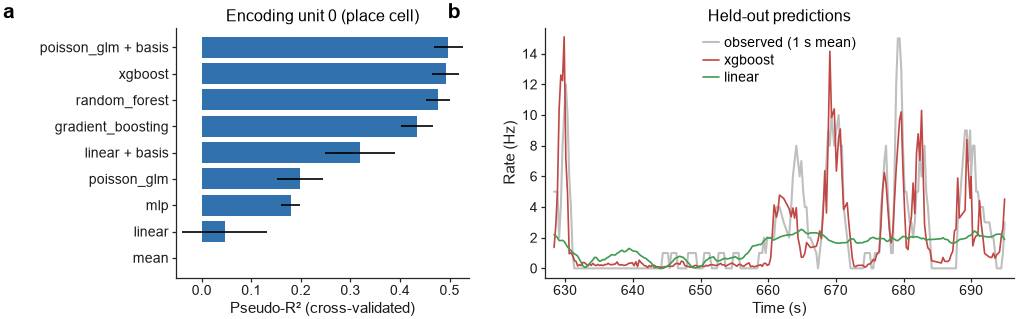

In [4]:
fig, (a, b) = plt.subplots(1, 2, figsize=style.figsize('double', height_mm=55),
                           gridspec_kw={'width_ratios': [1, 1.6]})
a.barh(table['model'], table['pseudo_r2'], xerr=table['sem'], color=style.CYCLE[0])
a.invert_yaxis()
a.set(xlabel='Pseudo-R² (cross-validated)', title=f'Encoding unit {unit} (place cell)')
style.panel_label(a, 'a', x=-0.55)

busy = int(np.argmax(np.convolve(counts[unit], np.ones(240), mode='valid')))
span = slice(busy, busy + 240)              # the minute the cell fires most
smooth = np.convolve(counts[unit].to_numpy(), np.ones(4) / 4, mode='same')
b.plot(t[span], smooth[span] / 0.25, color=style.GREYS['light'], lw=1, label='observed (1 s mean)')
for name, colour in (('xgboost', style.CYCLE[1]), ('linear', style.CYCLE[2])):
    b.plot(t[span], results[name].predicted[span] / 0.25, color=colour, label=name)
b.set(xlabel='Time (s)', ylabel='Rate (Hz)', title='Held-out predictions')
b.legend()
style.panel_label(b, 'b')

## Encoding the whole population

A Poisson GLM on the basis features, for every neuron. Tuned cells are well predicted, untuned cells score about 0, as they should.

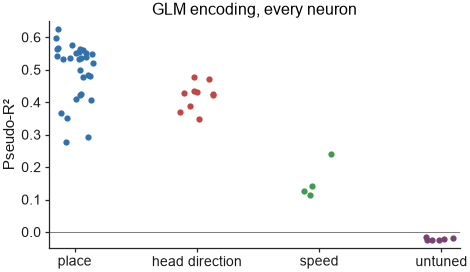

In [5]:
scores = ml.encode_population('poisson_glm', basis, counts)
scores = scores.merge(tuning[['unit', 'type']], left_on='neuron', right_on='unit')

fig, ax = plt.subplots(figsize=style.figsize(90, height_mm=50))
types = ['place', 'head_direction', 'speed', 'untuned']
for i, kind in enumerate(types):
    s = scores.query('type == @kind')['pseudo_r2']
    ax.plot(np.full(len(s), i) + np.random.default_rng(i).uniform(-0.15, 0.15, len(s)), s, 'o',
            ms=3, color=style.CYCLE[i])
ax.axhline(0, color=style.GREYS['mid'], lw=0.5)
ax.set(xticks=range(len(types)), xticklabels=[k.replace('_', ' ') for k in types],
       ylabel='Pseudo-R²', title='GLM encoding, every neuron');

## Decoding position, speed and head direction from the population

Now the population is the input and behaviour the target. `'mean'` is the floor every decoder must beat.
Its R² is below 0 because test blocks come from different parts of the session than the training data.

In [6]:
decoders = ['mean', 'ridge', 'random_forest', 'gradient_boosting', 'xgboost', 'mlp']
x_table, x_results = ml.compare(decoders, counts, beh['P_x'], task='continuous')
s_table, _ = ml.compare(decoders, counts, beh['S'], task='continuous')
h_table, h_results = ml.compare(decoders, counts, beh['H'], task='circular')
(x_table.set_index('model')[['r2']].rename(columns={'r2': 'x position R²'})
 .join(s_table.set_index('model')[['r2']].rename(columns={'r2': 'speed R²'}))
 .join(h_table.set_index('model')[['median_error_deg']]
       .rename(columns={'median_error_deg': 'head direction error (°)'})).round(3))

,x position R²,speed R²,head direction error (°)
model,,,
gradient_boosting,0.529,0.441,17.300
xgboost,0.517,0.453,17.182
mlp,0.512,0.390,20.075
random_forest,0.467,0.450,17.508
ridge,0.354,0.480,16.505
mean,-0.424,-0.004,96.926


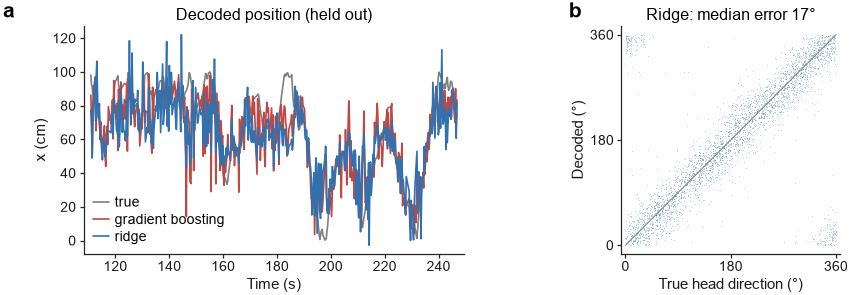

In [7]:
fig, (a, b) = plt.subplots(1, 2, figsize=style.figsize('double', height_mm=50))
span = slice(400, 880)
a.plot(t[span], beh['P_x'].to_numpy()[span], color=style.GREYS['mid'], label='true')
a.plot(t[span], x_results['gradient_boosting'].predicted[span], color=style.CYCLE[1],
       label='gradient boosting')
a.plot(t[span], x_results['ridge'].predicted[span], color=style.CYCLE[0], label='ridge')
a.set(xlabel='Time (s)', ylabel='x (cm)', title='Decoded position (held out)')
a.legend()
style.panel_label(a, 'a')
b.plot(np.degrees(beh['H']), np.degrees(h_results['ridge'].predicted), '.', ms=1,
       alpha=0.4, color=style.CYCLE[0])
b.plot([0, 360], [0, 360], color=style.GREYS['mid'], lw=0.5)
b.set(xlabel='True head direction (°)', ylabel='Decoded (°)', xticks=[0, 180, 360],
      yticks=[0, 180, 360], aspect='equal',
      title=f"Ridge: median error {h_results['ridge'].score:.0f}°")
style.panel_label(b, 'b');

## Decoding a category

Any labels work: here, which half of the arena the animal is in.

In [8]:
half = np.where(beh['P_x'] > 50, 'east', 'west')
cat_table, _ = ml.compare(['mean', 'logistic', 'random_forest', 'xgboost'], counts, half,
                          task='categorical')
cat_table

,model,accuracy,sem
0,logistic,0.892484,0.012879
1,xgboost,0.888124,0.011105
2,random_forest,0.845430,0.012044
3,mean,0.431849,0.091959


## Is a score better than chance?

`shuffle_test` re-scores with the target shifted in time against the features by a random offset. The shift keeps each signal's own smoothness, which a random permutation would destroy, so the null isn't too easy to beat.

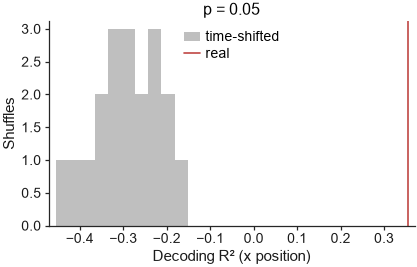

In [9]:
real, null, p = ml.shuffle_test('ridge', counts, beh['P_x'], task='continuous', n_shuffles=19)
fig, ax = plt.subplots(figsize=style.figsize(80, height_mm=45))
ax.hist(null, bins=10, color=style.GREYS['light'], label='time-shifted')
ax.axvline(real.score, color=style.CYCLE[1], label='real')
ax.set(xlabel='Decoding R² (x position)', ylabel='Shuffles', title=f'p = {p:.2f}')
ax.legend();

## History features (optional)

`ml.history` adds each variable's recent past through raised-cosine filters (as in Benjamin et al. 2018). Use it for covariate history, or a neuron's own spike history. With history features, leave a gap around each test block (`gap=` the history length in bins) so no training bin overlaps the test data. These simulated spikes have no dependence on their own past, so spike history doesn't help here. Real neurons often have bursts and refractory periods, and then it does.

In [10]:
own_past = ml.history(counts[unit], n_bases=4, max_lag_bins=8, name='self')
with_history = ml.cross_validate('poisson_glm', basis.join(own_past), counts[unit], gap=8)
without = ml.cross_validate('poisson_glm', basis, counts[unit], gap=8)
print(f'GLM: {without.score:.3f} without spike history, {with_history.score:.3f} with')

GLM: 0.496 without spike history, 0.493 with


## Your own data

The same calls work on any session in Raphael's processed tree:

```python
from raphael import ml, population
from raphael.ephys.layout import Session

session = Session(mouse='25', day='18', session_type='OF1')
pop = population.load(session.folder(root) / f'{session.stem}_srt-kilosort4').accepted()
behaviour = ...        # your project's behaviour loader: P_x, P_y, H, S as pynapple Tsd, a `moving` epoch

t, counts = ml.bin_counts(pop, binsize=0.25, ep=behaviour['moving'])
beh = ml.behaviour_at(behaviour, ['P_x', 'P_y', 'H', 'S'], t, circular=['H'])
```

Calcium imaging works the same way: `population.load` returns dF/F, and `bin_counts` averages it per bin. Use `task='continuous'` rather than `'encode'` for dF/F, since it isn't counts.